# Bank churn: who will leave, why, and whom to call
### A Kaggle churn notebook reproduced, audited and taken from a prediction to a retention decision

**The finding.** The source notebook's model is already good. Tuning it, which is where most
churn notebooks spend their effort, adds **+0.008 AUC** (0.860 → 0.868 on 2,000 held-out
customers, 95% CI +0.001 to +0.015). In this analysis that is worth no money. What is worth money is the step the
source notebook skips: **turning probabilities into a decision.** Keep the source's own model,
replace its default 0.5 cut-off with a rule that weighs each customer's churn risk against what
they are worth and what the call costs, and the retention campaign's profit on the same 2,000
customers rises from **€150k to €215k (+43%, 95% CI +€44k to +€89k)**. That is 70% of what a campaign
with perfect hindsight could earn, against 49% before.

Three more results change what a bank would do:
1. **Who leaves is not what the source notebook says.** Churn rises with product count only
   past two products: one product churns at 28%, two at 8%, and three or four at 83–100%. Customers
   holding three or more products are almost all leaving, which points at a product or mis-selling
   problem, not a retention problem.
2. **High-risk customers are at risk for different reasons.** Clustering the model's explanations
   finds three groups (older inactive customers, single-product German customers, and
   customers with 3+ products). Each needs a different action.
3. **An interpretable model is nearly as good.** A logistic regression that respects the shapes the
   EDA found reaches 0.853 AUC against the boosted model's 0.868. It is the version a bank's
   model-risk team could sign off.

**Data:** 10,000 real bank customers (France, Germany, Spain; public, CC0), the parent of the
Kaggle competition data the source notebook used. **Money figures rest on stated assumptions**
(deposit margin, offer cost, save rate), and §8 shows where the recommendation would flip.

## 1. The question, and what this notebook adds to the source

A retail bank loses about **1 in 5 customers**. The retention team can call a limited number of
customers and offer them a fee waiver. **The decision:** *which customers should get the call?*

The [source notebook](https://www.kaggle.com/code/artrocha/customer-churn-prediction-challange-shap-explain)
answers a narrower question, *how well can churn be predicted?* It uses a clean, standard pipeline:
80/20 split, scaling + one-hot encoding, 5-fold CV over Logistic Regression / Random Forest / LightGBM,
holdout evaluation and SHAP. This notebook reproduces it on the same split and folds, then continues:

| Step | Source notebook | This notebook |
|---|---|---|
| EDA | target balance, `describe()` | churn by segment **with confidence intervals**, effect sizes, the Germany / zero-balance confound |
| Models | LR, RF, LightGBM, defaults | + raw-unit trees, engineered features, XGBoost, an interpretable scorecard |
| Tuning | Optuna written but commented out | Optuna run (40 trials), with a **bug fix** in the search space |
| Evaluation | one holdout AUC, report at 0.5 | bootstrap CIs, **paired** model comparison, calibration, lift, per-segment fairness |
| SHAP | beeswarm on standardised features | beeswarm & dependence **in euros and years**, reason codes per customer, **risk personas** |
| Decision | none (probabilities to a CSV) | **value-aware targeting**, profit curves, sensitivity analysis, A/B test sizing, a call list |

Sub-questions, one per section: *What drives churn (§3)? Can the source pipeline be beaten, and
by how much (§4–5)? Can the probabilities be trusted, and for everyone (§6)? Why is each customer
at risk (§7)? Whom do we call, and what is it worth (§8)?*

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))     # the project root, so `src` imports
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

from src import acquisition, business, config, eda, evaluate, explain, features, figures, models

## 2. Data

**Source:** *Bank Turnover Dataset* (`barelydedicated/bank-customer-churn-modeling` on Kaggle,
CC0 public domain): 10,000 customers of a European bank, one row each, with whether they left
(`Exited`). It is the public parent of the
[Customer Churn Prediction Challenge](https://www.kaggle.com/competitions/churn-competition-pdc)
data the source notebook used. That competition file is a 25k-row derivative with added noise
(non-integer `CustomerId`s, for example) and sits behind the competition's rules gate. The
original is traceable, licence-clean and can be attached to a public notebook.

`src/acquisition.py` downloads it through Kaggle's public dataset endpoint, checks the SHA-256
against the pinned value (so every number below was produced on the same bytes), and validates
the schema: columns, types, no missing values, binary target, one row per customer.

In [2]:
df = acquisition.load_raw()
print(f"{df.shape[0]:,} customers × {df.shape[1]} columns   |   churn rate {df[config.TARGET].mean():.1%}")
display(df.head(3))
eda.data_quality(df)

10,000 customers × 14 columns   |   churn rate 20.4%


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.000,1,1,1,"101,348.880",1
1,2,15647311,Hill,608,Spain,Female,41,1,"83,807.860",1,0,1,"112,542.580",0
2,3,15619304,Onio,502,France,Female,42,8,"159,660.800",3,1,0,"113,931.570",1


,check,value
0,rows,10000
1,missing values,0
2,duplicate customers (CustomerId),0
3,duplicate feature rows,0
4,customers with Balance = 0,3617
5,German customers with Balance = 0,0
6,"EstimatedSalary below 1,000",59


The data is clean in the narrow sense: no missing values, no duplicates. Two things in the
quality table matter later:
- **36% of customers have a balance of exactly 0**, and **none of them are German**. Every
  German customer holds money with the bank. So "zero balance" and "not German" are partly the
  same fact, and any effect attributed to one is partly the other.
- **59 customers have an `EstimatedSalary` below €1,000** (minimum €11.58). For an annual salary
  that is implausible. `EstimatedSalary` turns out to carry no signal (§3), so this goes
  in the limitations rather than being fixed.

## 3. What drives churn

Churn rate by segment, each with a 95% Wilson interval: a rate on 60 customers is drawn as less
certain than one on 5,000. Bars more than 1.5× the overall rate are red.

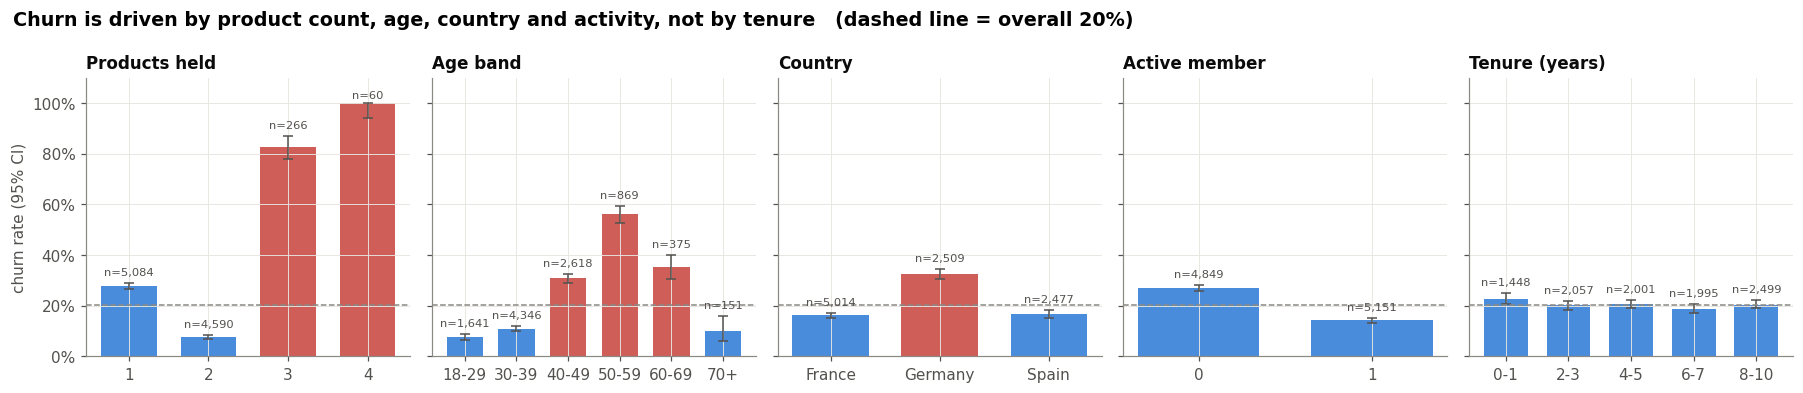

,churned,customers,churn_rate,ci_low,ci_high
NumOfProducts,,,,,
1,1409,5084,0.277,0.265,0.290
2,348,4590,0.076,0.069,0.084
3,220,266,0.827,0.777,0.868
4,60,60,1.000,0.940,1.000


In [3]:
seg = {
    "Products held": eda.churn_by(df, "NumOfProducts"),
    "Age band": eda.churn_by(df, eda.age_bands(df["Age"]), "Age"),
    "Country": eda.churn_by(df, "Geography"),
    "Active member": eda.churn_by(df, "IsActiveMember"),
    "Tenure (years)": eda.churn_by(df, pd.cut(df["Tenure"], [-1, 1, 3, 5, 7, 10],
                                               labels=["0-1", "2-3", "4-5", "6-7", "8-10"]), "Tenure"),
}
figures.save(figures.churn_by_segment(seg, df[config.TARGET].mean()), "01_churn_by_segment")
plt.show()
seg["Products held"]

What each panel says, and the modelling decision it drives:
- **Products held is U-shaped, not monotone.** 1 product: 28%; 2 products: 8%; 3: 83%; 4: 100%
  (all 60). Read as a number in a linear model, it would be forced to say "more products → more
  churn" or the reverse, and both are wrong. → *Treat it as categories in the scorecard; trees
  handle it natively.* The 3–4 product group is small (326 customers) but its rate is far outside
  any noise.
- **Age is a hump.** Churn climbs from 8% under 30 to 56% in the 50s, then falls back to 10% past 70.
  → *A single linear age coefficient cannot bend; the scorecard uses a spline.*
- **Germany churns at twice the rate** of France and Spain (32% vs 16–17%).
- **Inactive members churn at nearly twice the rate** of active ones (27% vs 14%).
- **Tenure is flat** (17–23% in every band). Time with the bank, on its own, says little.

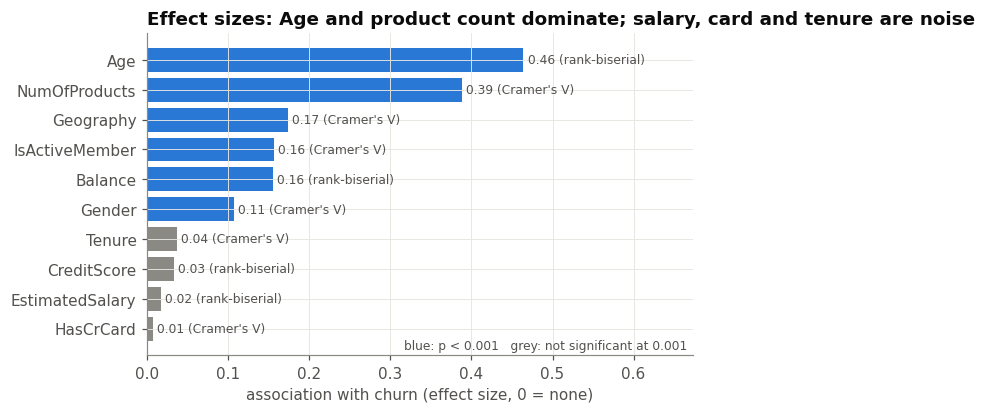

,feature,test,p_value,effect,effect_size
0,Age,Mann-Whitney U,0.000,rank-biserial,0.464
1,NumOfProducts,chi-square,0.000,Cramer's V,0.388
2,Geography,chi-square,0.000,Cramer's V,0.174
3,IsActiveMember,chi-square,0.000,Cramer's V,0.156
4,Balance,Mann-Whitney U,0.000,rank-biserial,0.155
5,Gender,chi-square,0.000,Cramer's V,0.107
6,Tenure,chi-square,0.178,Cramer's V,0.037
7,CreditScore,Mann-Whitney U,0.020,rank-biserial,-0.033
8,EstimatedSalary,Mann-Whitney U,0.227,rank-biserial,0.017
9,HasCrCard,chi-square,0.475,Cramer's V,0.007


In [4]:
assoc = eda.association_table(df)
figures.save(figures.effect_sizes(assoc), "02_effect_sizes"); plt.show()
assoc

With 10,000 rows almost any difference is "statistically significant", so the column to read is
the **effect size**. Age (rank-biserial 0.46: a random churner is older than a random stayer
73% of the time) and product count (Cramér's V 0.39) dominate. **`EstimatedSalary`, `HasCrCard`
and `Tenure` are indistinguishable from noise**, and `CreditScore` is negligible. The models
will confirm this independently through SHAP in §7.

One confound needs to be named before any model sees it:

In [5]:
conf = df.assign(ZeroBalance=(df["Balance"] == 0)).groupby(["Geography", "ZeroBalance"])[config.TARGET] \
         .agg(churn_rate="mean", customers="size").unstack("ZeroBalance")
conf

churn_rate       customers          
ZeroBalance      False True      False     True 
Geography                                       
France           0.182 0.139 2,596.000 2,418.000
Germany          0.324   NaN 2,509.000       NaN
Spain            0.196 0.136 1,278.000 1,199.000

Pooled over all countries, zero-balance customers churn *less* (14% vs 24%). Within France and
Spain the gap shrinks, and Germany, the high-churn country, has no zero-balance customers at all. Part of the "balance
effect" is the country effect in disguise. A model will happily split the credit between
`Balance` and `Geography_Germany`, and SHAP will report whatever split the model chose. That
is one reason §7 reads SHAP as *what the model uses*, not *what causes churn*.

## 4. Reproducing the source notebook

Same 80/20 stratified split, same seed (42), same preprocessing (`StandardScaler` on numerics,
one-hot with `drop='first'` on country and gender), same three default models, same 5 folds.
Everything that chooses anything, from models and features to hyperparameters and cut-offs, uses only
the 8,000 training customers. The 2,000 holdout customers are scored once, in §6.

In [6]:
X, y = features.split_xy(df)
X_train, X_test, y_train, y_test = features.holdout_split(X, y)
print(f"train {X_train.shape[0]:,} ({y_train.mean():.1%} churn)  |  holdout {X_test.shape[0]:,} ({y_test.mean():.1%} churn)")

cv = {}
for name, pipe in models.source_baselines().items():
    cv[f"Source: {name}"] = models.cv_evaluate(pipe, X_train, y_train)
models.cv_table(cv)

train 8,000 (20.4% churn)  |  holdout 2,000 (20.3% churn)


,model,auc,auc_sd,pr_auc,pr_auc_sd,brier,brier_sd,log_loss,log_loss_sd
0,Source: LightGBM,0.858,0.011,0.690,0.028,0.104,0.005,0.344,0.015
1,Source: Random Forest,0.851,0.011,0.670,0.016,0.107,0.004,0.381,0.028
2,Source: Logistic Regression,0.763,0.020,0.469,0.031,0.136,0.004,0.431,0.012


The ranking matches the source notebook (LightGBM > Random Forest > Logistic Regression). The
level does not: the source reports ~0.93 AUC on its competition file, against ~0.86 here. The
competition data is a different, noise-added derivative, so **absolute AUCs across the two
files are not comparable**. The comparison that matters runs the same pipeline on the
same data, which is what this section does.

The striking number is logistic regression at **0.76**, ten points behind the trees. §3 explains
why: it is given `Age` and `NumOfProducts` as straight lines, and neither relationship is straight.

## 5. Improving the model, and measuring each change

Each candidate changes one thing, so its effect can be read off on its own:

| Candidate | What changes vs. source LightGBM | Why |
|---|---|---|
| LightGBM, raw units | no scaling; every country its own column | trees ignore scaling; raw units make SHAP readable in € and years |
| + engineered features | `ZeroBalance`, `BalancePerProduct`, `TenureByAge`, `MultiProduct3Plus` | each answers something in §3 (`src/features.py`) |
| XGBoost | a second boosting library | is LightGBM's lead a library effect? |
| Scorecard LR | spline on Age, products as categories, zero-balance flag | can an *interpretable* model close the gap, given the right shapes? |
| LightGBM, tuned | Optuna, 40 trials of 5-fold CV | the step the source wrote but never ran |

**A bug fixed on the way.** The source's Optuna space tunes `subsample`, but LightGBM ignores
`subsample` unless `subsample_freq > 0`, which the source never sets. That part of its search did
nothing. Here `subsample_freq=1`.

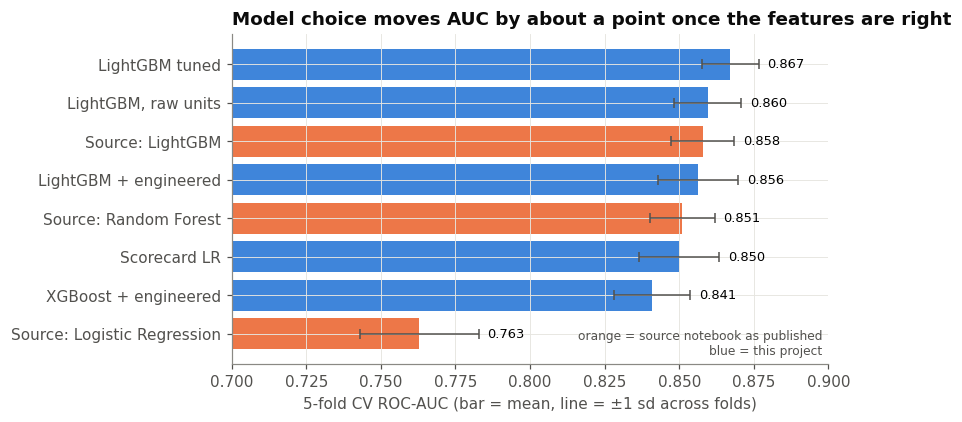

tuned hyperparameters: {'learning_rate': 0.0108, 'n_estimators': 403, 'max_depth': 5, 'num_leaves': 33, 'min_child_samples': 31, 'subsample': 0.7502, 'colsample_bytree': 0.5509, 'reg_lambda': 0.054, 'subsample_freq': 1}


,model,auc,auc_sd,pr_auc,pr_auc_sd,brier,brier_sd,log_loss,log_loss_sd
0,LightGBM tuned,0.867,0.009,0.704,0.020,0.102,0.004,0.336,0.010
1,"LightGBM, raw units",0.860,0.011,0.692,0.025,0.104,0.005,0.343,0.015
2,Source: LightGBM,0.858,0.011,0.690,0.028,0.104,0.005,0.344,0.015
3,LightGBM + engineered,0.856,0.013,0.685,0.031,0.105,0.006,0.347,0.018
4,Source: Random Forest,0.851,0.011,0.670,0.016,0.107,0.004,0.381,0.028
5,Scorecard LR,0.850,0.013,0.671,0.019,0.108,0.004,0.352,0.011
6,XGBoost + engineered,0.841,0.013,0.662,0.034,0.113,0.007,0.386,0.022
7,Source: Logistic Regression,0.763,0.020,0.469,0.031,0.136,0.004,0.431,0.012


In [7]:
cv["LightGBM, raw units"]        = models.cv_evaluate(models.tree_pipeline(models.lgbm(), engineered=False), X_train, y_train)
cv["LightGBM + engineered"]      = models.cv_evaluate(models.tree_pipeline(models.lgbm()), X_train, y_train)
cv["XGBoost + engineered"]       = models.cv_evaluate(models.tree_pipeline(models.xgb()), X_train, y_train)
cv["Scorecard LR"]               = models.cv_evaluate(models.scorecard_pipeline(), X_train, y_train)

best_params, study = models.tune_lgbm(X_train, y_train, n_trials=40)
cv["LightGBM tuned"]             = models.cv_evaluate(models.tree_pipeline(models.lgbm(**best_params)), X_train, y_train)

cv_tab = models.cv_table(cv)
figures.save(figures.model_comparison(cv_tab, {k for k in cv if k.startswith("Source")}), "03_model_comparison")
plt.show()
print("tuned hyperparameters:", {k: round(v, 4) if isinstance(v, float) else v for k, v in best_params.items()})
cv_tab

Four readings:
1. **The scorecard closes almost the whole gap.** Logistic regression jumps from 0.76 to 0.85
   just by being told that age bends and that product count is categorical. That is the
   largest single improvement in this table, and it came from the EDA, not from tuning.
2. **Engineered features add nothing to LightGBM** (within a fold's noise). Trees already find
   the zero-balance spike and the product cliff by splitting. The features still earn their place
   in the scorecard, which cannot split.
3. **XGBoost at default settings is worse than LightGBM at defaults.** That gap is
   default-hyperparameter luck, not a property of the library.
4. **Tuning buys about one point of AUC.** Small, but it is the best model on every metric,
   including Brier score and log-loss, which measure the *probabilities* rather than the ranking.
   §8 uses the probabilities directly, so they matter.

**Should the model use gender?** `Gender` is a legitimate predictor here, but using a protected
attribute to decide who gets an offer is a policy choice, not a modelling one. The question is
what dropping it costs:

In [8]:
pipe_ng = models.tree_pipeline(models.lgbm(**best_params), exclude=("Gender",))
cv_ng = models.cv_evaluate(pipe_ng, X_train, y_train)
print(f"tuned LightGBM, with gender   : CV AUC {cv['LightGBM tuned']['mean']['auc']:.4f}")
print(f"tuned LightGBM, gender removed: CV AUC {cv_ng['mean']['auc']:.4f}   "
      f"(cost {cv['LightGBM tuned']['mean']['auc'] - cv_ng['mean']['auc']:+.4f})")

tuned LightGBM, with gender   : CV AUC 0.8671
tuned LightGBM, gender removed: CV AUC 0.8649   (cost +0.0022)


Removing gender costs well under a point of AUC. A bank could reasonably decide that is a price
worth paying, especially under the EU AI Act's scrutiny of automated decisions about people. This
notebook keeps gender in the main model so it stays comparable with the source, and §6 checks
that the model works equally well for women and men.

## 6. The holdout: scored once

Three models go to the 2,000 untouched customers: the source's LightGBM (the baseline), the
tuned LightGBM (the candidate), and the scorecard (the interpretable alternative). Every
comparison is a **paired bootstrap**: resample the same customers 2,000 times and score both
models on each resample. Both models face the same easy and hard customers, so the noise they
share cancels and the interval reflects only their difference.

In [9]:
final = models.tree_pipeline(models.lgbm(**best_params)).fit(X_train, y_train)
source = models.source_baselines()["LightGBM"].fit(X_train, y_train)
scorecard = models.scorecard_pipeline().fit(X_train, y_train)

p_final  = final.predict_proba(X_test)[:, 1]
p_source = source.predict_proba(X_test)[:, 1]
p_score  = scorecard.predict_proba(X_test)[:, 1]

rows = []
for name, p in [("Source LightGBM", p_source), ("Tuned LightGBM", p_final), ("Scorecard LR", p_score)]:
    auc, lo, hi = evaluate.bootstrap_ci(y_test, p)
    rows.append({"model": name, "AUC": auc, "AUC 95% CI": f"[{lo:.3f}, {hi:.3f}]",
                 **{k: v for k, v in evaluate.holdout_metrics(y_test, p).items() if k != "auc"}})
holdout = pd.DataFrame(rows)
d_tuned = evaluate.paired_delta(y_test, p_final, p_source)
d_score = evaluate.paired_delta(y_test, p_final, p_score)
print(f"tuned − source   : ΔAUC {d_tuned['delta']:+.4f}  95% CI [{d_tuned['ci_low']:+.4f}, {d_tuned['ci_high']:+.4f}]")
print(f"tuned − scorecard: ΔAUC {d_score['delta']:+.4f}  95% CI [{d_score['ci_low']:+.4f}, {d_score['ci_high']:+.4f}]")
holdout

tuned − source   : ΔAUC +0.0077  95% CI [+0.0012, +0.0146]
tuned − scorecard: ΔAUC +0.0145  95% CI [+0.0048, +0.0242]


,model,AUC,AUC 95% CI,pr_auc,brier,ece
0,Source LightGBM,0.860,"[0.839, 0.880]",0.704,0.102,0.016
1,Tuned LightGBM,0.868,"[0.847, 0.888]",0.717,0.100,0.024
2,Scorecard LR,0.853,"[0.832, 0.875]",0.691,0.105,0.022


The holdout confirms cross-validation: the tuned model beats the source by **+0.008 AUC**,
an interval that excludes zero but is small, and the scorecard sits 0.015 behind. All three rank
customers well. The question that matters for a retention budget is not which model ranks best
but **what happens when someone acts on the scores**. First, two checks that the scores are fit
to act on.

**The source notebook's cut-off.** Its classification report thresholds at 0.5:

In [10]:
pd.DataFrame([evaluate.at_threshold(y_test, p_source, 0.5)])

,threshold,flagged,tp,fp,fn,tn,precision,recall
0,0.500,270,203,67,204,1526,0.752,0.499


At 0.5 the source model flags 270 customers and **misses half of all churners** (204 of 407).
0.5 is the threshold that minimises *misclassifications*, as if a missed churner and an
unnecessary call cost the same. They don't: a lost depositor is worth thousands, a call is worth
€130. §8 sets the threshold from those costs.

**Calibration**: if the model says 30%, do 30% leave? §8 multiplies probabilities by euros, so
this has to hold.

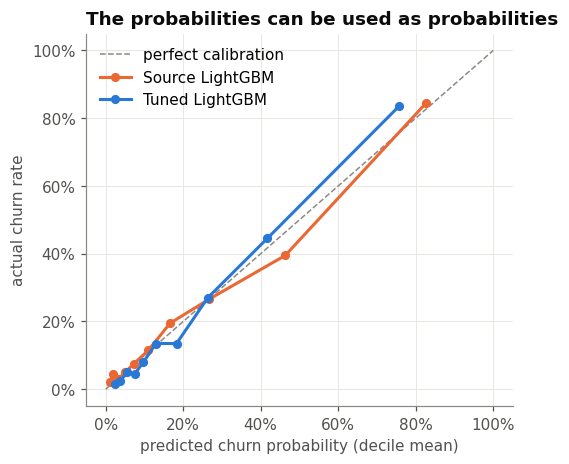

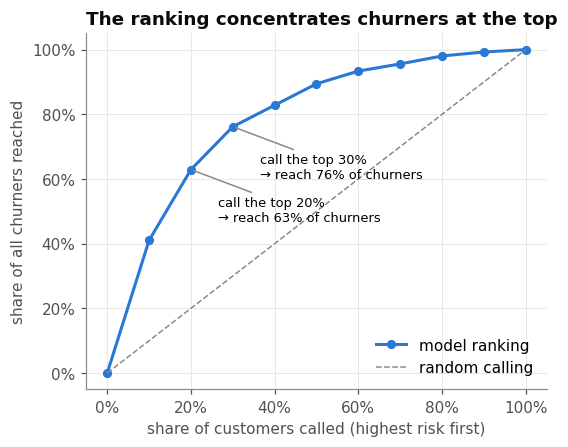

,customers,churners,mean_p,churn_rate,lift,cum_share_of_churners
decile,,,,,,
1,200,167,0.757,0.835,4.103,0.410
2,200,89,0.417,0.445,2.187,0.629
3,200,54,0.263,0.270,1.327,0.762
4,200,27,0.183,0.135,0.663,0.828
5,200,27,0.130,0.135,0.663,0.894
6,200,16,0.097,0.080,0.393,0.934
7,200,9,0.075,0.045,0.221,0.956
8,200,10,0.055,0.050,0.246,0.980
9,200,5,0.038,0.025,0.123,0.993


In [11]:
cal = {"Source LightGBM": evaluate.calibration_table(y_test, p_source),
       "Tuned LightGBM": evaluate.calibration_table(y_test, p_final)}
figures.save(figures.calibration(cal), "04_calibration"); plt.show()
lift = evaluate.lift_table(y_test, p_final)
figures.save(figures.gains(lift), "05_gains"); plt.show()
lift

Calibration is good, with an expected calibration error of about 2 points. The top decile is slightly *under*-predicted
(76% predicted, 84% actual), so the value calculation in §8 is, if anything, conservative for the
riskiest customers. The ranking is sharp: the top 10% of customers by risk churn at 4.1× the
average, and **calling the top 30% reaches 76% of all churners.**

**Does it work for everyone?** A model can rank well overall and badly within a group:

In [12]:
pd.concat([evaluate.segment_performance(X_test, y_test, p_final, "Geography"),
           evaluate.segment_performance(X_test, y_test, p_final, "Gender")], ignore_index=True)

,segment,customers,churn_rate,mean_predicted,auc
0,Geography = France,1021,0.171,0.164,0.857
1,Geography = Germany,504,0.300,0.312,0.870
2,Geography = Spain,475,0.171,0.176,0.871
3,Gender = Female,930,0.251,0.236,0.864
4,Gender = Male,1070,0.163,0.176,0.864


AUC is 0.86–0.87 in every country and identical for women and men, and each group's average
prediction tracks its real churn rate within about 2 points. No segment is being systematically
over- or under-flagged.

## 7. Why each customer is at risk

SHAP splits each prediction into additive contributions, one per feature, in log-odds:
*base rate + sum of contributions = this customer's predicted risk*. Because the trees here
train on raw features, every axis below is in real units: years, euros, product counts. The
source notebook's SHAP ran on standardised inputs, so its plots read "Age = 1.3" (a z-score) and its
dependence plot could not be read in years.

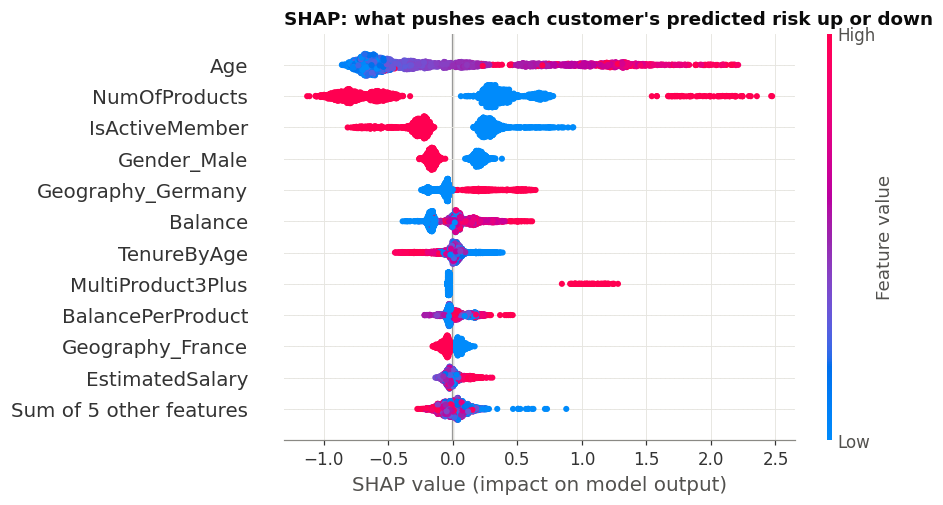

,mean |SHAP|
Age,0.648
NumOfProducts,0.594
IsActiveMember,0.303
Gender_Male,0.182
Geography_Germany,0.147
Balance,0.123
TenureByAge,0.073
MultiProduct3Plus,0.070


In [13]:
ex = explain.shap_explanation(final, X_test)
figures.save(figures.shap_beeswarm(ex), "06_shap_beeswarm"); plt.show()
explain.global_importance(ex).to_frame("mean |SHAP|").head(8)

Age, product count and activity lead, followed by gender and Germany. Salary, credit
score, tenure and card ownership sit near zero, as the effect sizes in §3 predicted, so two independent
methods agree.

**Correcting the source's reading.** The source concludes that "customers with more products
tend to increase the model prediction". The dependence plots show the shape the beeswarm hides:

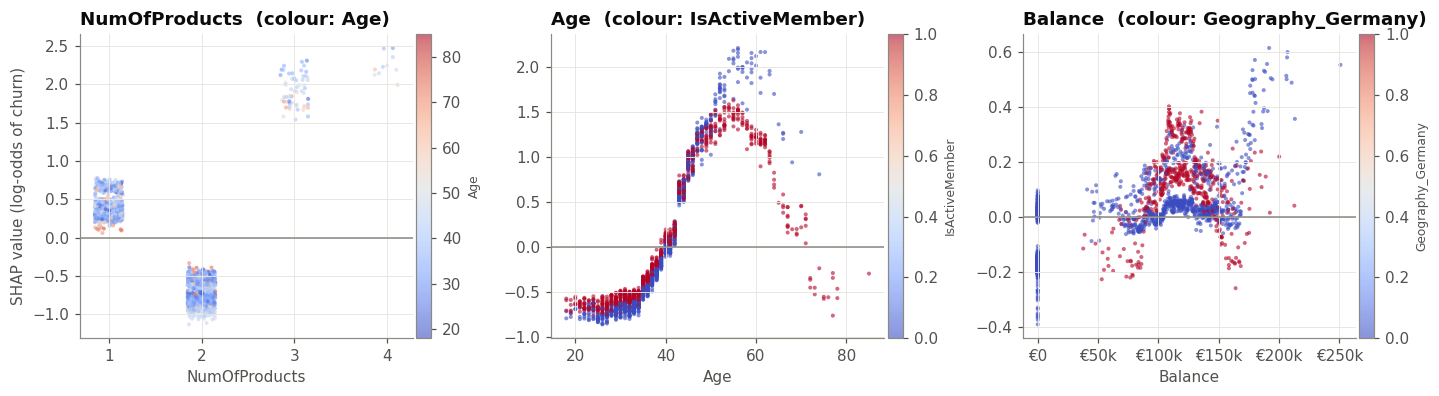

,mean SHAP,customers
NumOfProducts,,
1.000,0.386,1013
2.000,-0.721,918
3.000,1.917,59
4.000,2.242,10


In [14]:
fig = figures.shap_dependence(ex, ["NumOfProducts", "Age", "Balance"],
                              {"NumOfProducts": "Age", "Age": "IsActiveMember", "Balance": "Geography_Germany"})
figures.save(fig, "07_shap_dependence"); plt.show()

names = list(ex.feature_names)
j = names.index("NumOfProducts")
pd.Series(ex.values[:, j]).groupby(ex.data[:, j]).agg(["mean", "size"]).rename_axis("NumOfProducts") \
  .rename(columns={"mean": "mean SHAP", "size": "customers"})

- **Products:** one product pushes risk *up*, two pushes it strongly *down*, three or four push
  it sharply up. "More products → more churn" is wrong for most of the portfolio. The
  second product is the most protective thing a customer can hold.
- **Age:** a hump peaking in the mid-50s. The colour shows an interaction: from about 45 on,
  inactive members (blue) sit well above active ones (red) at the same age, while under 40 the
  difference is small and slightly reversed. Activity matters most in exactly the age band that
  churns most, which is where a re-engagement campaign should aim.
- **Balance:** a zero balance lowers risk slightly. Balances around €100–130k raise it, mostly for
  German customers (red), which is the confound from §3 showing up inside the model. Very large
  balances (above ~€170k) raise it for everyone. One hypothesis to test: large depositors gain
  the most from switching to a better rate.

A source-notebook error belongs here too: its dependence-plot commentary describes **Age**, but
the code above it plots **EstimatedSalary**.

**From a score to a reason code.** A retention advisor needs to know what to talk about, not
just a probability. Here is the riskiest holdout customer, decomposed:

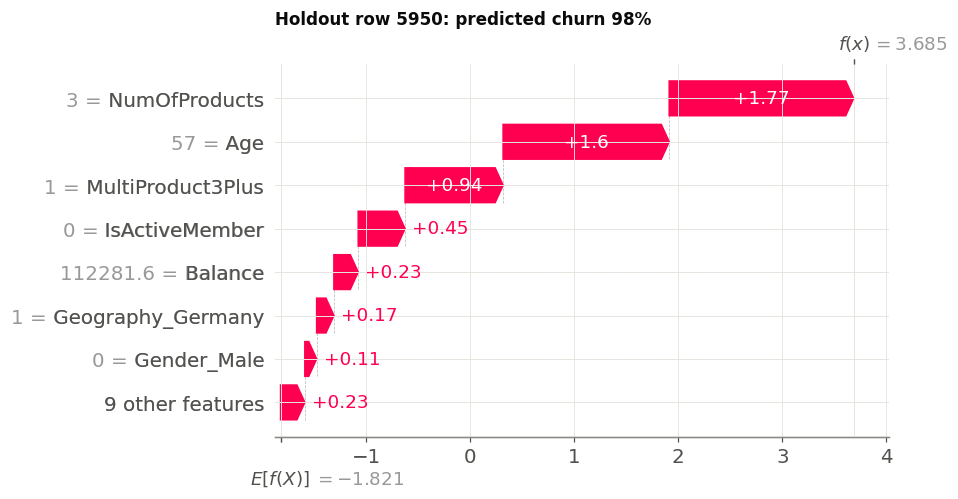

,predicted churn,reason code (top drivers)
5950,0.976,NumOfProducts = 3 (+1.77); Age = 57 (+1.60); 3...
70,0.974,NumOfProducts = 4 (+1.99); Age = 58 (+1.53); 3...
6255,0.974,NumOfProducts = 3 (+1.74); Age = 55 (+1.65); 3...
3549,0.971,NumOfProducts = 3 (+1.71); Age = 61 (+1.71); 3...
6831,0.968,NumOfProducts = 3 (+1.79); Age = 52 (+1.31); 3...
9540,0.960,NumOfProducts = 4 (+2.14); 3+ products (+1.05)...


In [15]:
top = int(np.argmax(p_final))
figures.save(figures.shap_waterfall(ex[top], f"Holdout row {X_test.index[top]}: predicted churn {p_final[top]:.0%}"),
             "08_shap_waterfall"); plt.show()
codes = explain.reason_codes(ex)
pd.DataFrame({"predicted churn": p_final, "reason code (top drivers)": codes}, index=X_test.index) \
  .sort_values("predicted churn", ascending=False).head(6)

**Risk personas.** The 500 highest-risk customers (top quarter) are not one group. Clustering
their *SHAP vectors*, rather than their raw features, groups customers by **why** the model flags
them. SHAP values share one unit (log-odds), so no scaling is needed, and the number of clusters
is chosen by silhouette score rather than by eye.

k = 3 clusters (silhouette by k: 3: 0.40, 4: 0.34, 5: 0.37, 6: 0.37)


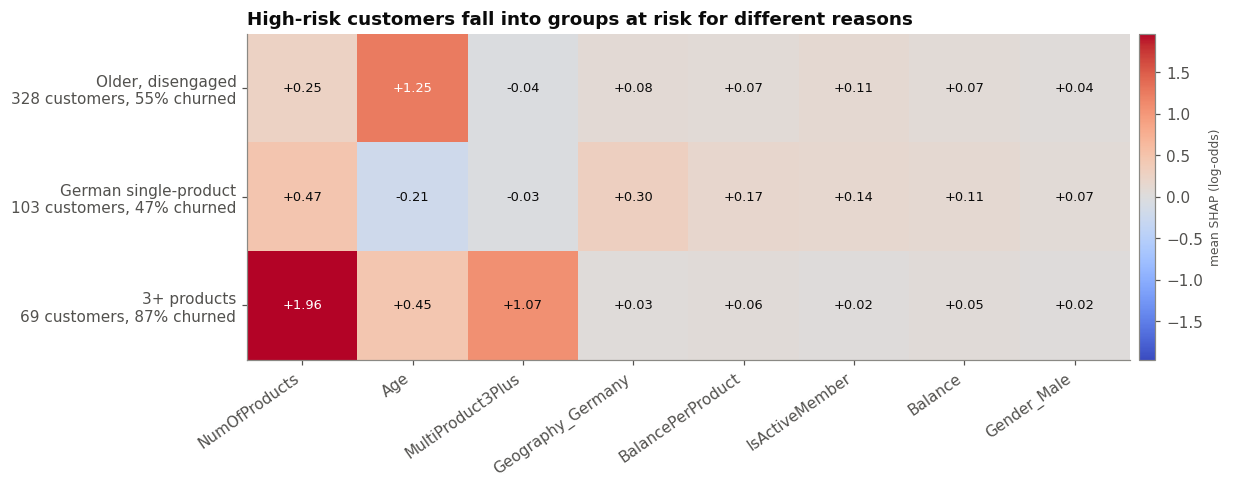

,name,customers,actual_churn,predicted_churn,median_age,share_inactive,share_germany,share_1_product,share_3plus_products,top_drivers
0,"Older, disengaged",328,0.555,0.523,48.000,0.613,0.381,0.835,0.000,"Age (+1.25), NumOfProducts (+0.25), IsActiveMe..."
1,German single-product,103,0.466,0.347,39.000,0.728,0.650,1.000,0.000,"NumOfProducts (+0.47), Geography_Germany (+0.3..."
2,3+ products,69,0.870,0.821,43.000,0.565,0.333,0.000,1.000,"NumOfProducts (+1.96), MultiProduct3Plus (+1.0..."


In [16]:
high_risk = p_final >= np.quantile(p_final, 0.75)
labels, k, sil = explain.personas(ex, high_risk)
profile = explain.persona_profile(ex, high_risk, labels, y_test, p_final)
profile["name"] = profile.apply(explain.name_persona, axis=1)
persona_names = dict(zip(profile["persona"], profile["name"]))
print(f"k = {k} clusters (silhouette by k: {', '.join(f'{kk}: {s:.2f}' for kk, s in sil.items())})")
figures.save(figures.persona_heatmap(ex, high_risk, labels, profile, persona_names), "09_personas"); plt.show()
profile[["name", "customers", "actual_churn", "predicted_churn", "median_age", "share_inactive",
         "share_germany", "share_1_product", "share_3plus_products", "top_drivers"]]

Three groups, three different conversations:

| Persona | Why at risk | What the bank would do |
|---|---|---|
| **Older, disengaged** (largest) | age 45+, mostly inactive | re-engagement: an advisor review, a product that fits life stage (pension, savings) |
| **German single-product** | one product, German, holds a balance | a competitive second product. Two products is the most protective state in §7 |
| **3+ products** | holds 3–4 products; 87% actually left | **not a call list**: an investigation. Near-certain churn after buying more products suggests mis-selling or a broken bundle |

The third row is the one to bring to a client. A model-driven campaign would call these
customers first, because they have the highest scores, but a fee waiver will not fix whatever is
driving them out. That is a root-cause question for the product team.

*SHAP explains the model, not the world.* "Inactive raises predicted risk" is a fact about the
model. "Activating customers would keep them" is a causal claim that needs an experiment (§8).

## 8. From probabilities to a decision: whom to call

**The economics of one call** (`src/business.py`; every input is an assumption in `src/config.py`):

| Input | Value | Meaning |
|---|---|---|
| customer value | 3 yrs × (1.5% × balance + €60 × products) | deposit margin plus product fees, over a 3-year horizon |
| cost per call | €30 call + €100 fee waiver = **€130** | the waiver goes to *everyone* called, including those who would have stayed |
| save rate | **20%** | share of would-be churners the offer actually keeps |

Call customer *i* if **p_i × 20% × value_i > €130**. Two consequences:
1. The break-even probability for an *average* customer (value ≈ €3,700) is
   130 / (0.2 × 3,700) ≈ **0.18**, not 0.5.
2. The break-even differs per customer. 40% risk on a €150k depositor clears it easily; 60%
   risk on an empty one-product account never does (0.6 × 0.2 × €180 = €22 < €130).

Five policies, all fixed *before* looking at who actually left, then scored on what the 2,000
holdout customers really did:

mean customer value (train): €3,712   |   break-even cut-off: 0.175


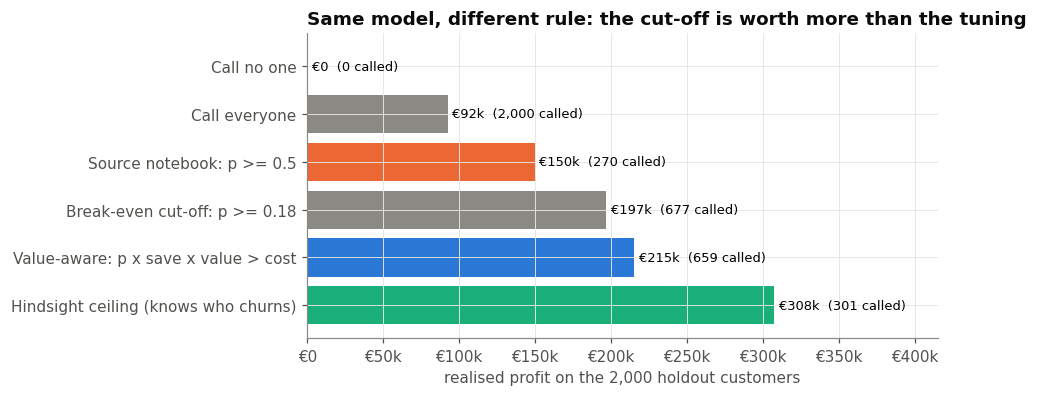

,policy,called (source model),profit (source model),called (tuned model),profit (tuned model)
0,Call no one,0,0.000,0,0.000
1,Call everyone,2000,"92,478.977",2000,"92,478.977"
2,Source notebook: p >= 0.5,270,"149,997.244",226,"138,124.068"
3,Break-even cut-off: p >= 0.18,677,"196,949.903",719,"192,408.250"
4,Value-aware: p x save x value > cost,659,"215,419.579",765,"213,286.508"
5,Hindsight ceiling (knows who churns),301,"307,768.977",301,"307,768.977"


In [17]:
value_test = business.customer_value(X_test)
mean_value_train = business.customer_value(X_train).mean()
print(f"mean customer value (train): €{mean_value_train:,.0f}   |   break-even cut-off: "
      f"{business.break_even_threshold(mean_value_train):.3f}")

pol_final = business.policy_table(y_test, p_final, value_test, mean_value_train)
pol_source = business.policy_table(y_test, p_source, value_test, mean_value_train)
compare = pol_source[["policy", "targeted", "profit"]].rename(columns={"targeted": "called (source model)", "profit": "profit (source model)"}) \
    .merge(pol_final[["policy", "targeted", "profit"]].rename(columns={"targeted": "called (tuned model)", "profit": "profit (tuned model)"}), on="policy")
figures.save(figures.policy_bars(pol_source), "10_policy_profit"); plt.show()
compare

In [18]:
pols = business.policies(y_test, p_source, value_test, mean_value_train)
names = list(pols)
rule_gain = business.bootstrap_policy_delta(y_test, value_test, pols[names[4]], pols[names[2]])
value_gain = business.bootstrap_policy_delta(y_test, value_test, pols[names[4]], pols[names[3]])
pols_f = business.policies(y_test, p_final, value_test, mean_value_train)
model_gain = business.bootstrap_policy_delta(y_test, value_test, pols_f[names[4]], pols[names[4]])
ceiling = pol_source.set_index("policy")["profit"][names[5]]
for label, g in [("value-aware rule vs 0.5 cut-off (source model)", rule_gain),
                 ("value-aware rule vs break-even cut-off (source model)", value_gain),
                 ("tuned model vs source model (both value-aware)", model_gain)]:
    print(f"{label:55s} {g['delta']:+10,.0f} €   95% CI [{g['ci_low']:+,.0f}, {g['ci_high']:+,.0f}]")
va = pol_source.set_index("policy")["profit"]
print(f"\nshare of hindsight ceiling: 0.5 cut-off {va[names[2]] / ceiling:.0%}  →  value-aware {va[names[4]] / ceiling:.0%}")

value-aware rule vs 0.5 cut-off (source model)             +65,422 €   95% CI [+43,716, +88,847]
value-aware rule vs break-even cut-off (source model)      +18,470 €   95% CI [+8,890, +29,198]
tuned model vs source model (both value-aware)              -2,133 €   95% CI [-10,041, +5,934]

share of hindsight ceiling: 0.5 cut-off 49%  →  value-aware 70%


This is the main result of the notebook:
- **Changing the rule is worth +€65k** on 2,000 customers (+43%), and the interval is far from zero.
  Most of that comes from lowering the cut-off from 0.5 to the break-even 0.18. Weighting by each
  customer's value then adds a further +€18k.
- **Changing the model is worth nothing.** With the value-aware rule, the tuned model earns
  €2k *less* than the source model, an interval centred on zero. Its extra AUC is real, but it
  reorders customers in a band where the decision does not change.
- The value-aware rule calls more customers than the 0.5 cut-off (659 vs 270) but **skips
  high-probability customers who are not worth saving**: it reaches fewer churners than the
  break-even cut-off (258 vs 321) yet earns more.

The profit curves show the same thing as a shape. Rank customers by probability (orange) or by
expected value (blue), call them in that order, and track the money:

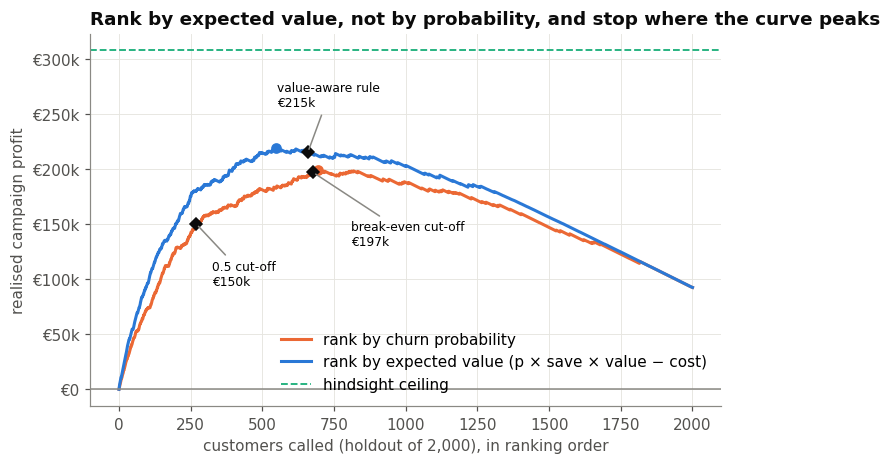

rank by churn probability                          peak €199,043 after 695 calls
rank by expected value (p × save × value − cost)   peak €218,848 after 546 calls


In [19]:
ev_source = business.expected_net(p_source, value_test)
curves = {"rank by churn probability": business.profit_curve(y_test, p_source, value_test),
          "rank by expected value (p × save × value − cost)": business.profit_curve(y_test, ev_source, value_test)}
markers = {"0.5 cut-off": (int(pols[names[2]].sum()), va[names[2]]),
           "break-even cut-off": (int(pols[names[3]].sum()), va[names[3]]),
           "value-aware rule": (int(pols[names[4]].sum()), va[names[4]])}
figures.save(figures.profit_curves(curves, markers, ceiling), "11_profit_curves"); plt.show()
for n, c in curves.items():
    peak = int(c["profit"].idxmax()); print(f"{n:50s} peak €{c['profit'].max():,.0f} after {peak:,} calls")

Ranking by expected value reaches a higher peak, and it reaches it by calling customers in a
better order, not by calling more of them. The value-aware rule stops close to that peak without having seen
the outcomes, because it stops exactly where the expected gain of the next call turns negative.

**Is the recommendation fragile?** It rests on three assumed numbers. Sweep the two most
uncertain, save rate and customer value, and recompute the gain of the value-aware rule over the 0.5 cut-off:

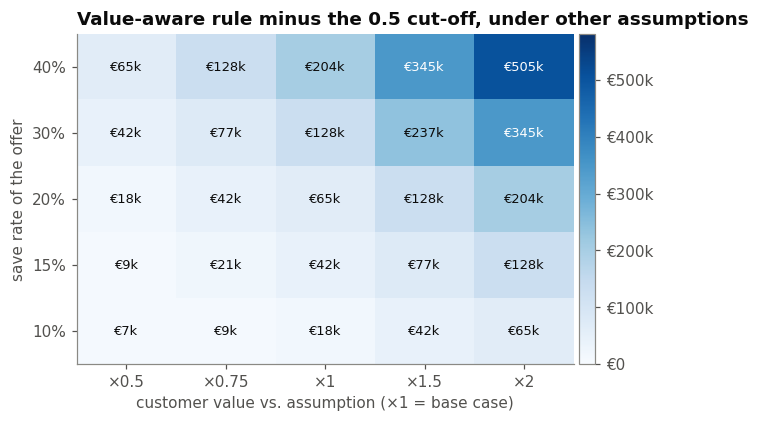

value-aware rule beats the 0.5 cut-off in 100% of the 25 scenarios; smallest gain €7,418


In [20]:
grid = business.sensitivity(
    y_test, p_source,
    value_fn=lambda m: business.customer_value(X_test, m),
    mean_value_fn=lambda m: business.customer_value(X_train, m).mean(),
    save_rates=[0.10, 0.15, 0.20, 0.30, 0.40], multipliers=[0.5, 0.75, 1.0, 1.5, 2.0])
figures.save(figures.sensitivity_heatmap(grid), "12_sensitivity"); plt.show()
print(f"value-aware rule beats the 0.5 cut-off in {(grid['gain_vs_source'] > 0).mean():.0%} of the {len(grid)} scenarios; "
      f"smallest gain €{grid['gain_vs_source'].min():,.0f}")

The value-aware rule wins in every one of the 25 scenarios, from a pessimistic 10% save rate on
half the assumed customer value to an optimistic 40% on double. The *size* of the gain depends on
the assumptions. Its *sign* does not. (The grid repeats along its diagonals because the rule only
ever uses save rate × value: 20% × double value is the same decision as 40% × base value. So a
client only has to estimate one number, the expected value saved per churner reached.)
That is how to present a money figure built on assumptions:
lead with the direction, give the size as a range, and name the inputs the client should replace
with their own.

**Where the value at risk sits:**

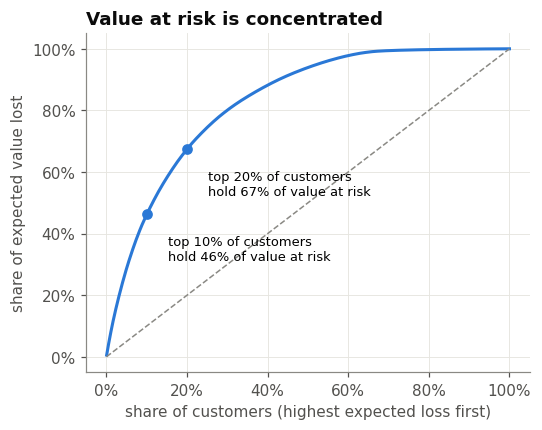

top 10% of customers: 46% of expected value lost; top 20%: 67%


In [21]:
conc = business.value_at_risk_concentration(p_final, value_test)
figures.save(figures.value_concentration(conc), "13_value_concentration"); plt.show()
print(f"top 10% of customers: {np.interp(0.1, conc.share_of_customers, conc.share_of_value_at_risk):.0%} of expected value lost; "
      f"top 20%: {np.interp(0.2, conc.share_of_customers, conc.share_of_value_at_risk):.0%}")

**Proving it before rolling it out.** Everything above assumes the 20% save rate. The only way
to *know* it is a randomised test: split the call list, call half, leave half alone, and compare
churn. This also answers the causal question SHAP cannot (§7). The sample size needed:

In [22]:
targeted_churn = y_test[pols[names[4]]].mean()
for rel in (0.10, 0.20, 0.30):
    n = business.ab_test_size(targeted_churn, rel)
    print(f"to detect a {rel:.0%} relative cut in churn (from {targeted_churn:.0%}): {n:,} customers per arm")

to detect a 10% relative cut in churn (from 39%): 2,392 customers per arm
to detect a 20% relative cut in churn (from 39%): 584 customers per arm
to detect a 30% relative cut in churn (from 39%): 252 customers per arm


At this bank's size (≈3,300 customers per 10,000 would be on the call list), a test for a 20% effect fits in
one campaign cycle. A test for a 10% effect would need roughly four times the sample.

**The deliverable a retention team would actually receive**, which takes the place of the source
notebook's `submission.csv`: a ranked call list with the probability, the value, the expected
gain and the reason code for each customer.

In [23]:
call_list = pd.DataFrame({
    "churn_probability": p_final, "customer_value_eur": value_test.round(0),
    "expected_gain_eur": business.expected_net(p_final, value_test).round(0),
    "reason_code": codes}, index=X_test.index)
call_list = call_list[call_list["expected_gain_eur"] > 0].sort_values("expected_gain_eur", ascending=False)
config.OUTPUTS.mkdir(exist_ok=True)
call_list.to_csv(config.OUTPUTS / "call_list_holdout.csv")
print(f"{len(call_list):,} of {len(X_test):,} holdout customers are worth a call")
call_list.head(8)

760 of 2,000 holdout customers are worth a call


,churn_probability,customer_value_eur,expected_gain_eur,reason_code
2092,0.833,"11,830.000","1,841.000",NumOfProducts = 3 (+2.25); 3+ products (+1.18)...
3175,0.895,"7,955.000","1,294.000",NumOfProducts = 3 (+2.29); 3+ products (+1.25)...
555,0.943,"7,513.000","1,287.000",NumOfProducts = 3 (+1.99); Age = 51 (+1.16); 3...
4784,0.819,"8,622.000","1,282.000",Age = 53 (+1.61); inactive member (+0.60); Bal...
2658,0.864,"7,963.000","1,246.000",NumOfProducts = 3 (+2.07); 3+ products (+1.14)...
4869,0.914,"7,277.000","1,201.000",NumOfProducts = 3 (+2.07); 3+ products (+1.17)...
2473,0.878,"7,522.000","1,191.000",Age = 57 (+1.94); inactive member (+0.64); Cre...
6831,0.968,"6,817.000","1,190.000",NumOfProducts = 3 (+1.79); Age = 52 (+1.31); 3...


## 9. Audit of the source notebook

What was found while reproducing it, in order of consequence. None of it is unusual in a
competition notebook. Most of it would matter in front of a client.

| # | Issue | Consequence | Fixed in |
|---|---|---|---|
| 1 | Stops at probabilities; evaluates at a 0.5 cut-off | misses half the churners; leaves €65k per 2,000 customers on the table | §8 |
| 2 | SHAP read as "more products → more churn" | wrong for 97% of customers; the effect is U-shaped | §7 |
| 3 | SHAP on standardised features | plots in z-scores, unreadable for a business audience | §5, §7 |
| 4 | Optuna tunes `subsample` without `subsample_freq` | that part of the search was a no-op | `src/models.py` |
| 5 | Optuna commented out, ROC still labelled "Optimized" | the published model is the default one | §5 |
| 6 | Dependence-plot text describes Age, code plots EstimatedSalary | the interpretation is of a plot that is not there | §7 |
| 7 | Logistic regression fed straight lines | understates the interpretable option by 9 AUC points | §5 |
| 8 | One holdout number, no interval, no paired comparison | can't tell whether LightGBM really beats Random Forest | §6 |
| 9 | No calibration check before probabilities are used | fine here (ECE ≈ 2 pts), but it had to be checked | §6 |
| 10 | Gender used without discussion | a governance question a bank must answer | §5–6 |
| 11 | Says MLflow tracks experiments; no MLflow code exists | documentation drift | — |

## 10. Limitations

- **The money is modelled, not measured.** Customer value, the €130 cost and the 20% save rate
  are assumptions. The sensitivity grid shows the recommendation's direction is robust to them;
  its size is not. A real engagement replaces them with the bank's own figures and a pilot.
- **A snapshot, not a history.** One row per customer with no dates: no way to know *when* a
  customer left, how recently they went inactive, or whether `Balance` was measured before or
  after the decision to leave. A production model needs point-in-time features to rule out leakage.
- **SHAP is not causal.** Personas describe why the *model* flags customers. Whether
  re-engaging an inactive customer keeps them is untested until the A/B test in §8 runs.
- **Small cells.** The 3–4 product group is 326 customers (60 with four products, all churned).
  The pattern is unambiguous, but its cause is unknown from this data.
- **One holdout of 2,000.** Bootstrap intervals cover sampling noise in that holdout, not a
  change in the customer base over time.
- **`EstimatedSalary` has implausible values** (59 below €1,000). It carries no signal, so
  it was left in rather than imputed.
- **Not the competition file.** The source's 0.93 AUC came from a noise-added derivative behind a
  rules gate. This analysis uses the clean public parent, so absolute AUCs differ. Every
  comparison here is like for like.

## 11. What I'd do about it

1. **Change the decision rule before changing the model.** Call customers whose expected saved
   value exceeds the cost of the call. In this analysis that is worth +43% campaign profit, and model tuning is worth ~0.
2. **Split the call list by persona.** Older, inactive customers get a re-engagement call;
   single-product German customers get a second-product offer.
3. **Take the 3+ product customers to the product team, not the call centre.** 83–100% of them leave.
   Find out what they were sold.
4. **Run the randomised test** (≈580 customers per arm for a 20% effect) to replace the assumed
   save rate with a measured one, and to establish whether the call *causes* retention.
5. **Ship the scorecard if model-risk sign-off is the constraint.** It gives up 0.015 AUC for
   coefficients a reviewer can read.

## 12. Reproduce

```bash
python -m venv .venv && .venv/Scripts/pip install -r requirements.txt   # Python 3.10
python run_analysis.py      # downloads the data, executes this notebook, regenerates the Kaggle notebook and the deck
pytest -q                   # unit tests for the src modules
```

Every figure in `outputs/figures/` is written by this notebook; the deck reads them from there.

The cell below re-checks every number quoted in the prose above against what this run computed.
If a future change moves a number, the notebook fails here instead of publishing stale text.

In [24]:
H = {
    "holdout AUC source": (holdout.loc[0, "AUC"], 0.860, 0.0005),
    "holdout AUC tuned": (holdout.loc[1, "AUC"], 0.868, 0.0005),
    "holdout AUC scorecard": (holdout.loc[2, "AUC"], 0.853, 0.0005),
    "ΔAUC tuned-source": (d_tuned["delta"], 0.008, 0.0005),
    "ΔAUC CI low": (d_tuned["ci_low"], 0.001, 0.0005),
    "ΔAUC CI high": (d_tuned["ci_high"], 0.015, 0.0005),
    "profit 0.5 cut-off (€k)": (va[names[2]] / 1000, 150, 0.5),
    "profit value-aware (€k)": (va[names[4]] / 1000, 215, 0.5),
    "rule gain CI low (€k)": (rule_gain["ci_low"] / 1000, 44, 0.5),
    "rule gain CI high (€k)": (rule_gain["ci_high"] / 1000, 89, 0.5),
    "share of ceiling 0.5": (va[names[2]] / ceiling, 0.49, 0.005),
    "share of ceiling value-aware": (va[names[4]] / ceiling, 0.70, 0.005),
    "personas": (k, 3, 0),
    "sensitivity wins": ((grid["gain_vs_source"] > 0).mean(), 1.0, 0),
    "A/B per arm, 20% effect (hundreds)": (business.ab_test_size(targeted_churn, 0.20) / 100, 5.8, 0.05),
    "rule gain (€k)": (rule_gain["delta"] / 1000, 65, 0.5),
    "value weighting gain (€k)": (value_gain["delta"] / 1000, 18, 0.5),
    "model gain, value-aware (€k)": (model_gain["delta"] / 1000, -2, 0.5),
}
bad = {k: round(v, 4) for k, (v, stated, tol) in H.items() if abs(v - stated) > tol}
assert not bad, f"prose is stale, recomputed values: {bad}"
print(f"all {len(H)} quoted numbers match this run")

all 18 quoted numbers match this run
